# DLW 半离散系统的非线性化与 2HS 数值比较

下面的代码载入本机已有的 Lean、Mathlib 和证明库。在 Colab 中选择“连接到本地运行时”，或在 VS Code 中选择本地 Python 内核。随后依次执行各路线的 import、起点和终点；数值部分在同一 Python 内核中逐段计算。输出保留在运行的单元下方，修改上游代码后重新运行受影响的后段。


In [1]:
# @title 载入本地 Lean 证明库
import sys
sys.path.insert(0, "C:/Users/msz/aca/Workspaces/report_colab_20261006")

from report_runtime import load_lean
lean_notebook_session = load_lean()


## 1　DLW 半离散系统的非线性化

### 1.1　消去辅助势的两场形式

载入 (u, ω) 与 (u, v) 非线性化的定义、证明及已编译的证明库。


In [2]:
%%lean uw import
import ReportNonlinearUW


Lean proof import: Contracts (warm_cache)


Lean proof import: PkgNonlinear (warm_cache)


Lean proof import: PkgLattice (warm_cache)


Lean proof import: ReportNonlinearUW (warm_cache)


考虑交错格点上的双线性方程

$$B_{a-h/2}F_j\cdot G_j=0,\qquad B_{a+h/2}F_j\cdot G_{j+1}=0,\qquad B_s=D_x^2+D_t+2sD_x.\tag{1}$$

将理论的双线性起点写为 StartPoint，供下一段定理调用使用。


In [3]:
%%lean uw start
import StepUWImport

namespace DLWContract.ReportUW

def StartPoint (a h : ℝ) (F G : Lattice) : Prop :=
  ∀ j, bil (a-h/2) (F j) (G j) = 0 ∧
    bil (a+h/2) (F j) (G (j+1)) = 0

#print StartPoint

end DLWContract.ReportUW


def DLWContract.ReportUW.StartPoint : ℝ → ℝ → Lattice → Lattice → Prop :=
fun a h F G => ∀ (j : ℤ), bil (a - h / 2) (F j) (G j) = 0 ∧ bil (a + h / 2) (F j) (G (j + 1)) = 0


`def StartPoint` 写出式（1）的两条双线性假设；`#print StartPoint` 将这一定义输出。起点到终点的证明在后面的终点代码块中调用。

`namespace` 组织名称，`section` 管理作用域，`noncomputable section` 允许使用精确实数函数；这些声明负责组织代码。

其中 $D$ 为 Hirota 双线性算子，$F_j$ 与 $G_j$ 分别位于 $y=(j+\tfrac12)h$ 和 $y=jh$，$h\ne0$。在 $F_j,G_j$ 非零的区域内，令 $\alpha_j=\log F_j$、$\beta_j=\log G_j$。利用恒等式

$$\frac{B_sf\cdot g}{fg}=(\log f+\log g)_{xx}+(\log f-\log g)_x^2
+(\log f-\log g)_t+2s(\log f-\log g)_x,\tag{2}$$

将式（1）除以相应的 $\tau$ 函数乘积，得到

$$\begin{aligned}
A_j={}&(\alpha_j+\beta_j)_{xx}+(\alpha_j-\beta_j)_x^2+(\alpha_j-\beta_j)_t+(2a-h)(\alpha_j-\beta_j)_x=0,\\
C_j={}&(\alpha_j+\beta_{j+1})_{xx}+(\alpha_j-\beta_{j+1})_x^2+(\alpha_j-\beta_{j+1})_t+(2a+h)(\alpha_j-\beta_{j+1})_x=0.
\end{aligned}\tag{3}$$

取两侧对数差导数的和与差

$$u_j=(2\alpha_j-\beta_j-\beta_{j+1})_x,\qquad
\omega_j=(\beta_{j+1}-\beta_j)_x.\tag{4}$$

于是两侧对数差的导数分别为 $(u_j+\omega_j)/2$ 和 $(u_j-\omega_j)/2$。将式（3）相加、相减并对 $x$ 求导，记

$$Z_j=(2\alpha_j+\beta_j+\beta_{j+1})_x.\tag{5}$$

可得

$$\begin{aligned}
u_{j,t}+\partial_x\!\left[\frac{u_j^2+\omega_j^2}{2}+2au_j-h\omega_j\right]+Z_{j,xx}&=0,\\
\omega_{j,t}+[(u_j+2a)\omega_j-hu_j]_x-\omega_{j,xx}&=0.
\end{aligned}\tag{6}$$

定义 $\delta_-f_j=(f_j-f_{j-1})/h$、$M_-f_j=(f_j+f_{j-1})/2$。由式（4）有 $\delta_-Z_j=\delta_-u_j+(4/h)M_-\omega_j$，从而消去 $Z_j$，得到闭合的非线性半离散系统

$$\boxed{\begin{aligned}
\delta_-u_{j,t}+\partial_x\delta_-\!\left[\frac{u_j^2+\omega_j^2}{2}+2au_j-h\omega_j\right]
+\partial_x^2\left(\delta_-u_j+\frac4hM_-\omega_j\right)&=0,\\
\omega_{j,t}+\partial_x[(u_j+2a)\omega_j-hu_j]-\omega_{j,xx}&=0.
\end{aligned}}\tag{7}$$

为恢复连续 DLW 的物理变量，令 $v_j=(4/h)\omega_j+\delta_0u_j$，其中 $\delta_0f_j=(f_{j+1}-f_{j-1})/(2h)$。写 $W_j=v_j-\delta_0u_j$、$\Delta_hf_j=(f_{j+1}-2f_j+f_{j-1})/h^2$，式（7）等价地表示为

$$\begin{aligned}
0={}&\delta_-u_{j,t}
+\partial_x\delta_-\!\left[\frac{u_j^2}{2}+2au_j+h^2\left(\frac{W_j^2}{32}-\frac{W_j}{4}\right)\right]\\
&+\partial_x^2\left(M_-v_j-\frac{h^2}{4}\Delta_h\delta_-u_j\right),\\
0={}&v_{j,t}+\partial_x\!\left[\delta_0\!\left(\frac{u_j^2}{2}+2au_j+h^2\left(\frac{W_j^2}{32}-\frac{W_j}{4}\right)\right)
+(u_j+2a)W_j-4u_j\right]\\
&+\partial_x^2\left[\delta_0u_j+\frac{h^2}{4}\Delta_hW_j\right],
\end{aligned}\tag{8}$$

上述消元在有限 $h$ 下成立；在光滑连续极限中，式（8）趋于

$$u_{yt}+v_{xx}+[(u+2a)u_y]_x=0,\qquad
v_t+u_{xxy}+[(u+2a)v-4u]_x=0.\tag{9}$$

在 h≠0、F/G 严格为正且联合实解析的条件下，从 StartPoint 推出式 (7)、(8)，并显示原始公理依赖。

1. **输入。** `hsp : StartPoint a h F G` 是式（1）的假设，展开后与库中的 `SemiPair` 相同。`hh` 要求 h≠0；`hF/hG` 要求各格点的函数关于 (x,t) 联合实解析，`hFp/hGp` 要求严格为正。

2. **结论。** 第一个 `example` 的冒号后是 `reportN1 = 0 ∧ reportN2 = 0`，对应式（7）。第二个的 `NonlinearPair` 展开为 `n1 = 0 ∧ n2 = 0`，对应式（8）。

3. **使用起点。** 核心定理 `c15_proved` 中的 `rw [(hsp j).1]` 与 `rw [(hsp j).2]` 使用两条双线性方程，使归一化残差 `normA`、`normC` 为零；`c14_proved` 的残差恒等式随后给出 `NonlinearPair`。

4. **得到报告终点。** `semiPair_implies_report8` 用 `physical_v` 对齐 v 的重构后调用核心定理。`semiPair_implies_report7` 使用同一结论：`reportN1_eq_n1` 给出第一条；`c19_proved` 的 W 守恒律经 `omega_conservation_bridge` 变为 `(4/h)·reportN2 = 0`，再由 h≠0 得到第二条。

阅读每个 `example` 时，先看括号中的假设，再看冒号后的结论，最后看 `:=` 后提供证明的定理。这里的 `example` 证明任意满足假设的场；终点运行会检查这两个调用，`#print axioms` 输出它们依赖的基础公理。导数法则、差分恒等式与代数化简封装在导入的证明库中。


In [4]:
%%lean uw endpoint
import StepUWStart

noncomputable section
open DLWContract DLWContract.ReportUW

-- (7): equations for u and ω.
example (a h : ℝ) (F G : Lattice) (hh : h ≠ 0)
    (hF : SmoothL F) (hG : SmoothL G) (hFp : PositiveL F) (hGp : PositiveL G)
    (hsp : StartPoint a h F G) :
    reportN1 a h (physU F G) (omega G) = 0 ∧
      reportN2 a h (physU F G) (omega G) = 0 :=
  semiPair_implies_report7 a h F G hh hF hG hFp hGp hsp

-- (8): the reconstructed pair (u, v).
example (a h : ℝ) (F G : Lattice) (hh : h ≠ 0)
    (hF : SmoothL F) (hG : SmoothL G) (hFp : PositiveL F) (hGp : PositiveL G)
    (hsp : StartPoint a h F G) :
    NonlinearPair a h (physU F G) (vFromOmega h (physU F G) (omega G)) :=
  semiPair_implies_report8 a h F G hh hF hG hFp hGp hsp

#print axioms DLWContract.ReportUW.semiPair_implies_report7
#print axioms DLWContract.ReportUW.semiPair_implies_report8


'DLWContract.ReportUW.semiPair_implies_report7' depends on axioms: [propext, Classical.choice, Quot.sound]
'DLWContract.ReportUW.semiPair_implies_report8' depends on axioms: [propext, Classical.choice, Quot.sound]


关键证明封装在 `PkgNonlinear.lean` 与 `ReportNonlinearUW.lean`：`c15_proved` 使用两条双线性假设，将 `normA`、`normC` 置零；`c14_proved` 给出物理场残差恒等式，得到 `NonlinearPair`。`semiPair_implies_report8` 对齐 $v$ 的重构；`semiPair_implies_report7` 再通过 `reportN1_eq_n1` 与 `omega_conservation_bridge` 得到式（7）的两条方程。终点单元调用这些已证明的定理。

### 1.2　保留势的比值形式

本路线仍从式（1）出发，保留势与中心比值，经过下述公式推导到式（21）、（22）。

载入 (Q, R, M) 非线性化的定义、证明及已编译的证明库。


In [5]:
%%lean qrm import
import ReportNonlinearQRM


Lean proof import: Contracts (warm_cache)


Lean proof import: PkgLattice (warm_cache)


Lean proof import: PkgQuotientRate (warm_cache)


Lean proof import: ReportQRMCalculus (warm_cache)


Lean proof import: PkgNonlinear (warm_cache)


Lean proof import: ReportNonlinearUW (warm_cache)


Lean proof import: ReportNonlinearQRM (warm_cache)


将理论的双线性起点写为 StartPoint，供下一段定理调用使用。


In [6]:
%%lean qrm start
import StepQRMImport

namespace DLWContract.ReportQRM

def StartPoint (a h : ℝ) (F G : Lattice) : Prop :=
  ∀ j, bil (a-h/2) (F j) (G j) = 0 ∧
    bil (a+h/2) (F j) (G (j+1)) = 0

#print StartPoint

end DLWContract.ReportQRM


def DLWContract.ReportQRM.StartPoint : ℝ → ℝ → Lattice → Lattice → Prop :=
fun a h F G => ∀ (j : ℤ), bil (a - h / 2) (F j) (G j) = 0 ∧ bil (a + h / 2) (F j) (G (j + 1)) = 0


`def StartPoint` 写出式（1）的两条双线性假设；`#print StartPoint` 将这一定义输出。起点到终点的证明在后面的终点代码块中调用。

`namespace` 组织名称，`section` 管理作用域，`noncomputable section` 允许使用精确实数函数；这些声明负责组织代码。

保留辅助势 $M_j=\beta_{j,x}$，由式（4）、（5）得

$$\omega_j=M_{j+1}-M_j,\qquad
Z_j=u_j+2(M_j+M_{j+1}).\tag{10}$$

代入式（6），得

$$\begin{aligned}
0={}&u_{j,t}+\partial_x\!\left[
u_{j,x}+\frac{u_j^2}{2}+2au_j
+2(M_j+M_{j+1})_x+\frac{\omega_j^2}{2}-h\omega_j\right],\\
0={}&\omega_{j,t}-\omega_{j,xx}
+\partial_x[(u_j+2a)\omega_j-hu_j],\\
\omega_j={}&M_{j+1}-M_j.
\end{aligned}\tag{11}$$

固定对数分支，定义中心比值

$$Q_j=\exp\!\left(\alpha_j-\frac{\beta_j+\beta_{j+1}}2\right)
=\frac{F_j}{\sqrt{G_jG_{j+1}}},\qquad
u_j=2\frac{Q_{j,x}}{Q_j}.\tag{12}$$

其中 $Q_j$ 位于 $y=(j+\tfrac12)h$，$M_j$ 位于 $y=jh$。由此有

$$u_{j,t}=2\partial_x\!\left(\frac{Q_{j,t}}{Q_j}\right),\qquad
u_{j,x}+\frac{u_j^2}{2}=2\frac{Q_{j,xx}}{Q_j}.\tag{13}$$

式（11）的第一条化为

$$\partial_x\!\left[
\frac{Q_{j,t}+Q_{j,xx}+2aQ_{j,x}}{Q_j}
+(M_j+M_{j+1})_x+\frac{\omega_j^2}{4}-\frac h2\omega_j
\right]=0.\tag{14}$$

由式（12），括号内为 $(A_j+C_j)/2=0$，故

$$\begin{aligned}
0={}&Q_{j,t}+Q_{j,xx}+2aQ_{j,x}\\
&+\left[(M_j+M_{j+1})_x
+\frac{\omega_j^2}{4}-\frac h2\omega_j\right]Q_j,\\
0={}&\omega_{j,t}-\omega_{j,xx}
+\partial_x\!\left[2a\omega_j
+2\frac{Q_{j,x}}{Q_j}(\omega_j-h)\right],\\
\omega_j={}&M_{j+1}-M_j.
\end{aligned}\tag{15}$$

### 1.3　势差的乘积分解

令

$$R_j=\frac{1-\omega_j/h}{Q_j},\qquad
\omega_j=h(1-Q_jR_j),\qquad
\frac{M_{j+1}-M_j}{h}+Q_jR_j=1.\tag{16}$$

在 $Q_j\ne0$ 时，$(Q_{j,x}/Q_j)(\omega_j-h)=-hQ_{j,x}R_j$，且

$$\frac{\omega_j^2}{4}-\frac h2\omega_j
=\frac{h^2}{4}(Q_j^2R_j^2-1).\tag{17}$$

代入式（15），得

$$\begin{aligned}
0={}&Q_{j,t}+Q_{j,xx}+2aQ_{j,x}\\
&+\left[(M_j+M_{j+1})_x
+\frac{h^2}{4}(Q_j^2R_j^2-1)\right]Q_j,\\
0={}&(Q_jR_j)_t-(Q_jR_j)_{xx}
+2a(Q_jR_j)_x+2(Q_{j,x}R_j)_x.
\end{aligned}\tag{18}$$

利用恒等式

$$-(Q_jR_j)_{xx}+2(Q_{j,x}R_j)_x
=Q_{j,xx}R_j-Q_jR_{j,xx}.
\tag{19}$$

第二条可写为

$$R_j(Q_{j,t}+Q_{j,xx}+2aQ_{j,x})
+Q_j(R_{j,t}-R_{j,xx}+2aR_{j,x})=0.\tag{20}$$

再由式（18）的第一条，得到

$$\boxed{\begin{aligned}
0={}&Q_{j,t}+Q_{j,xx}+2aQ_{j,x}\\
&+\left[(M_j+M_{j+1})_x
+\frac{h^2}{4}(Q_j^2R_j^2-1)\right]Q_j,\\[2pt]
0={}&R_{j,t}-R_{j,xx}+2aR_{j,x}\\
&-\left[(M_j+M_{j+1})_x
+\frac{h^2}{4}(Q_j^2R_j^2-1)\right]R_j,\\[2pt]
1={}&\frac{M_{j+1}-M_j}{h}+Q_jR_j.
\end{aligned}}\tag{21}$$

物理场由下式恢复：

$$\boxed{\begin{aligned}
u_j&=2\frac{Q_{j,x}}{Q_j},\qquad
\omega_j=h(1-Q_jR_j)=M_{j+1}-M_j,\\
v_j&=4(1-Q_jR_j)+\frac{u_{j+1}-u_{j-1}}{2h}.
\end{aligned}}\tag{22}$$

在 h≠0、F/G 严格为正且联合实解析的条件下，从 StartPoint 推出式 (21)，给出式 (22) 的重构恒等式，并显示原始公理依赖。

1. **式（21）。** `semiPair_implies_report21` 接收 `StartPoint` 及相同的正则性、正性、h≠0 假设，合并 `report_Q_equation`、`report_R_equation` 与 `lattice_constraint`。

2. **证明关系。** Q 方程由归一化双线性残差归零得到；R 方程由乘积残差分解、Q 方程和式（7）的第二条得到。

3. **式（22）。** `report22` 合并 u、ω、v 的重构恒等式；这部分只依赖场的定义、正则性、正性与 h≠0。

冒号后给出结论，`:=` 后调用证明定理；关键证明与依赖保留在导入库中。


In [7]:
%%lean qrm endpoint
import StepQRMStart

noncomputable section
open DLWContract DLWContract.ReportQRM

-- (21): equations for Q and R, and the lattice constraint.
example (a h : ℝ) (F G : Lattice) (hne : h ≠ 0)
    (hF : SmoothL F) (hG : SmoothL G) (hFp : PositiveL F) (hGp : PositiveL G)
    (hsp : StartPoint a h F G) :
    residualQ a h F G = 0 ∧ residualR a h F G = 0 ∧
      ∀ j x t, (M G (j+1) x t-M G j x t)/h + Q F G j x t*R h F G j x t = 1 :=
  semiPair_implies_report21 a h F G hne hF hG hFp hGp hsp

-- (22): reconstruction of u, ω and v.
example (h : ℝ) (F G : Lattice) (hne : h ≠ 0)
    (hF : SmoothL F) (hG : SmoothL G) (hFp : PositiveL F) (hGp : PositiveL G) :
    ∀ j x t,
      physU F G j x t = 2 * lx (Q F G) j x t / Q F G j x t ∧
      omega G j x t = h*(1-Q F G j x t*R h F G j x t) ∧
      omega G j x t = M G (j+1) x t-M G j x t ∧
      physV h F G j x t = 4*(1-Q F G j x t*R h F G j x t) +
        (physU F G (j+1) x t-physU F G (j-1) x t)/(2*h) :=
  report22 h F G hne hF hG hFp hGp

#print axioms DLWContract.ReportQRM.semiPair_implies_report21
#print axioms DLWContract.ReportQRM.report22


'DLWContract.ReportQRM.semiPair_implies_report21' depends on axioms: [propext, Classical.choice, Quot.sound]
'DLWContract.ReportQRM.report22' depends on axioms: [propext, Classical.choice, Quot.sound]


关键证明封装在 `ReportNonlinearQRM.lean`：`report_Q_equation` 由双线性起点得到 $Q$ 方程；`report_R_equation` 使用乘积残差分解及式（7）的第二条得到 $R$ 方程；`semiPair_implies_report21` 合并两条演化方程与格点约束。`report22` 合并 $u$、$\omega$、$v$ 的重构恒等式。

## 2　2HS 单孤子与二孤子的数值比较

### 2.1　单孤子

考虑 $c=1$ 的 2HS 系统

$$u_{tx}-uu_{xx}-\frac12u_x^2-4u-\frac12(\rho^2-1)=0,\qquad \rho_t=(u\rho)_x.\tag{23}$$

取原文图 1、图 3 的参数 $p=5$、$q=1.25$、$\xi_0=\eta_0=0$，相应的连续单孤子解为

$$\theta=\frac{15}{4}X-\frac35t,\qquad
x=X-\frac12+\frac3{10}\tanh\frac\theta2,\qquad
u=\frac9{100}\operatorname{sech}^2\frac\theta2,\qquad
\rho=\frac{16}{25-9\tanh^2(\theta/2)}.\tag{24}$$

其中 $\rho$ 的远场值为 $1$。比较可积半离散格式（Integrable）与固定网格中心差分（FD）。取辅助节点 $X_k=-4+ka$，$a=0.005$、$k=0,\ldots,N$、$N=1600$；由式（24）给出初始物理节点与场值。FD 在相同的初始物理端点间均匀布点，物理步长记为 $\Delta x$。

**Integrable。** 令 $d_k=x_{k+1}-x_k$、$b_k=u_{k+1}-u_k$，采用原文式（100）的等价形式

$$\begin{aligned}
\dot d_k&=-b_k,\qquad \dot x_0=-u_0(t),\\
\dot b_k&=2d_k(u_{k+1}+u_k)
+\frac{[d_k^2-a(a-1)]^2-b_k^2}{2d_k}-\frac{d_k}{2}.
\end{aligned}\tag{25}$$

左端 $u_0(t)$ 取解析值；各节点及胞元密度由下式递推恢复：

$$u_{k+1}=u_k+b_k,\qquad x_{k+1}=x_k+d_k,\qquad
\rho_{k+1/2}=\frac{a}{d_k}.\tag{26}$$

**FD。** 对式（23）的第一式作 $x$ 微分，令 $m=u_{xx}+2$。在固定网格上定义

$$ (D_1f)_i=\frac{f_{i+1}-f_{i-1}}{2\Delta x},\qquad
(D_2f)_i=\frac{f_{i+1}-2f_i+f_{i-1}}{\Delta x^2},\tag{27}$$

并计算

$$\begin{aligned}
\dot m_i&=u_i(D_1m)_i+2m_i(D_1u)_i+\rho_i(D_1\rho)_i,\\
\dot\rho_i&=u_i(D_1\rho)_i+\rho_i(D_1u)_i,\\
u_{i+1}-2u_i+u_{i-1}&=\Delta x^2(m_i-2).
\end{aligned}\tag{28}$$

初始取 $m_i^0=(D_2u^0)_i+2$、$\rho_i^0=\rho(x_i,0)$。两端 $u,\rho,m$ 取解析值，每个时间级由最后一式联立求出内部 $u_i$。

两种系统均用 RK4 更新。记上述演化方程为 $\dot z=\mathcal F(t,z)$，则

$$\begin{aligned}
K_1&=\mathcal F(t_n,z^n),&
K_2&=\mathcal F\!\left(t_n+\frac{\Delta t}{2},z^n+\frac{\Delta t}{2}K_1\right),\\
K_3&=\mathcal F\!\left(t_n+\frac{\Delta t}{2},z^n+\frac{\Delta t}{2}K_2\right),&
K_4&=\mathcal F(t_n+\Delta t,z^n+\Delta tK_3),\\
z^{n+1}&=z^n+\frac{\Delta t}{6}(K_1+2K_2+2K_3+K_4).
\end{aligned}\tag{29}$$

每一级均按式（26）或（28）恢复物理场。取 $\Delta t=0.003125$，从 $t=0$ 计算至 $t=0.5$。

在 $x\in[-1,1]$ 的 32001 个等距点组成的集合 $\mathcal G$ 上，经线性插值后计算相对连续解的最大绝对误差：

$$E_u(t)=\max_{x\in\mathcal G}|u_h(x,t)-u(x,t)|,\qquad
E_\rho(t)=\max_{x\in\mathcal G}|\rho_h(x,t)-\rho(x,t)|.\tag{30}$$

表 1　单孤子在 t=0.5 时的最大绝对误差。

| 空间方案 | $E_u$ | $E_\rho$ |
| --- | --- | --- |
| 可积半离散（Integrable） | 1.0013e-02 | 1.1497e-03 |
| 中心差分（FD） | 9.3993e-07 | 3.0464e-06 |

FD 的双场误差均较小；Integrable 的 $\rho$ 误差为 FD 的 377.4 倍。

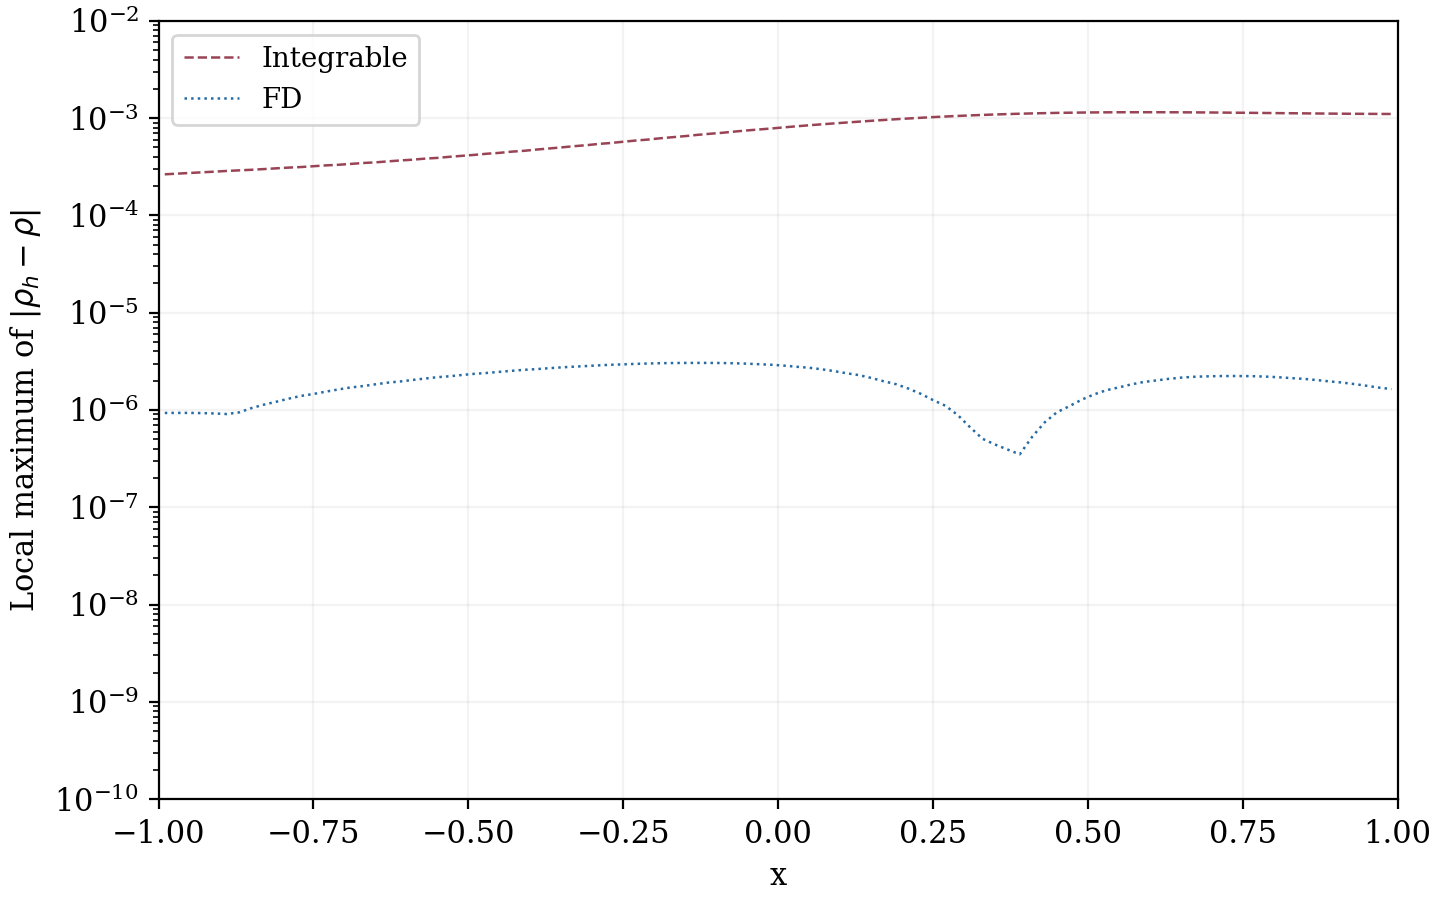

图 1　单孤子在 t=0.5 时的密度误差分布，每段宽 0.02，取段内最大绝对误差。

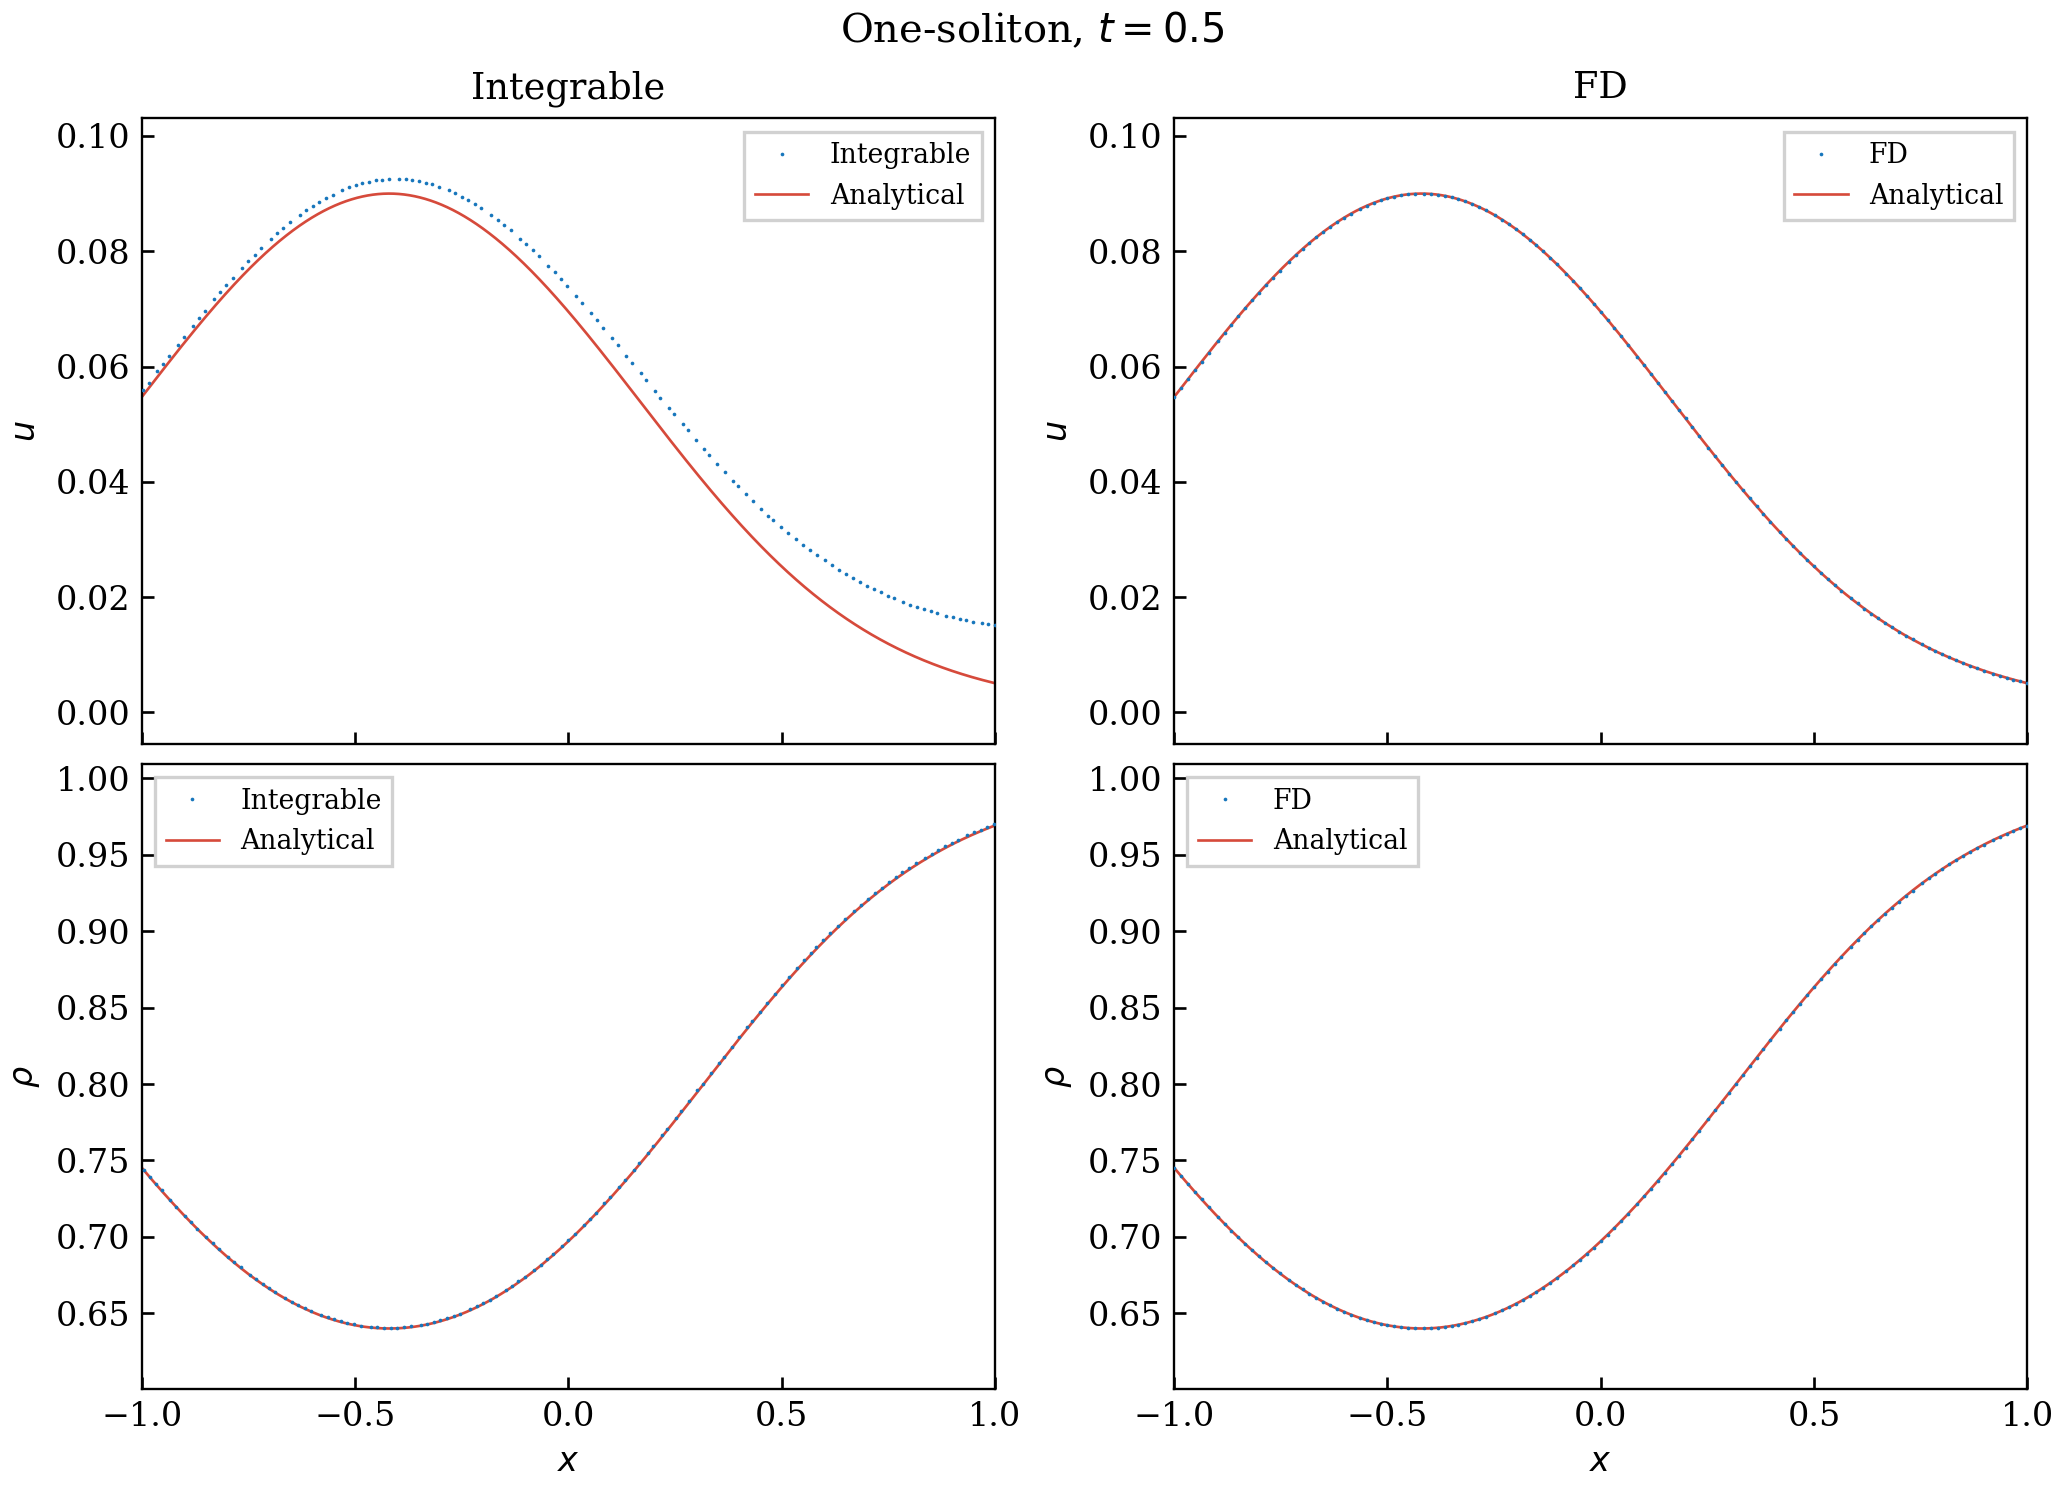

图 2　t=0.5 时的单孤子波形。左列为 Integrable，右列为 FD；上排为 u，下排为 ρ。红色实线为连续解析解，蓝色离散点为对应方案的数值解。

### 2.1.1　单孤子误差的现场计算

从准备环境、设置参数、定义连续参考解开始，逐段建立空间格式与 RK4，再实际推进单孤子，最后计算终点误差。每次点击 ▶ 只执行眼前这一段；已运行的定义保存在同一笔记本内核中。修改前面的代码后，依次重新运行受影响的后段。

默认采用原表的 $N=1600$、$a=0.005$、$\Delta t=0.003125$、$T=0.5$ 与 32001 个评价点。密度在 Integrable 的胞元中点与 FD 的节点上分别重构。以下代码使用 Python、NumPy 与 Matplotlib 计算；原表仅用于默认配置的回归核对。误差图每点取一个物理小区间的最大值，低于 $10^{-16}$ 的读数在图中共用显示下限。

检查计算所需的数学函数和双精度数组。


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 计算使用 IEEE 754 双精度。
np.set_printoptions(precision=12)
pd.set_option("display.precision", 12)


设置网格、RK4 时间步长和误差评价点。


In [9]:
# 式（24）：p=5、q=1.25、c=1，初相位为零。
# 加密同一辅助区间时，同时增大 N、减小 a。
hs_cfg = dict(
    N=1600, a=0.005, Xleft=-4.0,
    dt=0.003125, T=0.5,
    xMin=-1.0, xMax=1.0, evaluationPoints=32001,
)
hs_N, hs_a, hs_Xleft = (hs_cfg[k] for k in ("N", "a", "Xleft"))
hs_dt, hs_T = (hs_cfg[k] for k in ("dt", "T"))
hs_xmin, hs_xmax, hs_neval = (hs_cfg[k] for k in ("xMin", "xMax", "evaluationPoints"))
if not np.isfinite([hs_a, hs_Xleft, hs_dt, hs_T, hs_xmin, hs_xmax]).all():
    raise ValueError("网格、时间和评价区间须取有限实数。")
if not (hs_a > 0 and hs_dt > 0 and hs_T >= 0 and hs_xmax > hs_xmin):
    raise ValueError("要求 a>0、dt>0、T≥0、xMax>xMin。")
if not isinstance(hs_N, int) or not 20 <= hs_N <= 6400:
    raise ValueError("N 应为 20—6400 的整数。")
if not isinstance(hs_neval, int) or not 101 <= hs_neval <= 64001:
    raise ValueError("评价点数应为 101—64001 的整数。")
hs_steps = round(hs_T / hs_dt)
if abs(hs_steps * hs_dt - hs_T) > 1e-12 or hs_steps > 3200:
    raise ValueError("T 须为 dt 的整数倍，且步数≤3200。")
hs_Xright = hs_Xleft + hs_N * hs_a
print(pd.DataFrame([{
    "N": hs_N, "a": hs_a, "X 左端": hs_Xleft, "X 右端": hs_Xright,
    "dt": hs_dt, "T": hs_T, "时间步数": hs_steps, "评价点数": hs_neval,
}]).to_string(index=False))


   N     a  X 左端  X 右端       dt   T  时间步数  评价点数
1600 0.005  -4.0   4.0 0.003125 0.5   160 32001


定义单孤子解析解，并构造初始物理网格。


In [10]:
def hs_exact_X(X, t):
    """式（24）的解析场；X 可以是标量或数组。"""
    X = np.asarray(X, dtype=float)
    z = np.tanh((3.75 * X - 0.6 * t) / 2)
    S = 1 - z * z
    zX = 1.875 * S
    zXX = -2 * zX * 1.875 * z
    J, JX = 1 + 0.3 * zX, 0.3 * zXX
    u, uX = 0.09 * S, -0.18 * z * zX
    uXX = -0.18 * (zX * zX + z * zXX)
    # 链式法则：d/dx=(1/J)d/dX，其中 J=dx/dX。
    uxx = (uXX * J - uX * JX) / (J * J * J)
    return dict(x=X - 0.5 + 0.3 * z, u=u, rho=1 / J, m=uxx + 2, X=X)

def hs_exact_physical(x, t):
    """利用 dx/dX>0，在 [x+0.2,x+0.8] 中二分反解 X。"""
    x = np.asarray(x, dtype=float)
    lo, hi = x + 0.2, x + 0.8
    for _ in range(60):
        mid = (lo + hi) / 2
        lower = hs_exact_X(mid, t)["x"] < x
        lo, hi = np.where(lower, mid, lo), np.where(lower, hi, mid)
    value = hs_exact_X((lo + hi) / 2, t)
    if np.max(np.abs(value["x"] - x)) > 2e-12:
        raise ArithmeticError("物理坐标反解未达到容差。")
    return value

hs_initial = hs_exact_X(hs_Xleft + np.arange(hs_N + 1) * hs_a, 0)
hs_left, hs_right = hs_initial["x"][[0, -1]]
hs_dx = (hs_right - hs_left) / hs_N
# 固定网格与初始动网格共用物理端点。
hs_fixed_x = hs_left + np.arange(hs_N + 1) * hs_dx
if hs_xmin <= hs_left or hs_xmax >= hs_right:
    raise ValueError("评价区间必须位于初始物理端点内部。")
print(pd.DataFrame([{
    "初始物理左端": hs_left, "初始物理右端": hs_right,
    "FD 的 dx": hs_dx, "峰值 u": 0.09, "谷值 rho": 0.64,
}]).to_string(index=False))


         初始物理左端         初始物理右端        FD 的 dx  峰值 u  谷值 rho
-4.799999816459 3.799999816459 0.005374999771  0.09    0.64


定义两种空间格式，并由三对角方程从 m 恢复 u。


In [11]:
def hs_integrable_fields(t, state):
    # 状态：[b_0,...,b_(N-1), d_0,...,d_(N-1), x_0]。
    b, d = state[:hs_N], state[hs_N:2 * hs_N]
    if not np.isfinite(state).all() or np.any(d <= 0):
        raise ArithmeticError("Integrable 出现非有限状态或非正胞元格距。")
    u0 = hs_exact_X(hs_Xleft, t)["u"]
    u = np.r_[u0, u0 + np.cumsum(b)]
    x = np.r_[state[-1], state[-1] + np.cumsum(d)]
    return dict(x=x, u=u, rhoX=(x[:-1] + x[1:]) / 2, rho=hs_a / d)

def hs_integrable_rhs(t, state):
    # 式（25）：b、d 和 x_0 的时间导数。
    u = hs_integrable_fields(t, state)["u"]
    b, d = state[:hs_N], state[hs_N:2 * hs_N]
    C = d * d - hs_a * (hs_a - 1)
    db = 2 * d * (u[1:] + u[:-1]) + (C * C - b * b) / (2 * d) - d / 2
    return np.r_[db, -b, -u[0]]

def hs_recover_u(m, ub_left, ub_right):
    # Thomas 消元：u_(i-1)-2u_i+u_(i+1)=dx^2*(m_i-2)。
    count = hs_N - 1
    c, d = np.zeros(count), np.zeros(count)
    for j in range(count):
        diagonal = -2 - (c[j - 1] if j else 0)
        rhs = hs_dx * hs_dx * (m[j + 1] - 2)
        if j == 0:
            rhs -= ub_left
        if j == count - 1:
            rhs -= ub_right
        c[j] = 1 / diagonal if j < count - 1 else 0
        d[j] = (rhs - (d[j - 1] if j else 0)) / diagonal
    u = np.empty(hs_N + 1)
    u[0], u[-1] = ub_left, ub_right
    for j in range(count - 1, -1, -1):
        u[j + 1] = d[j] - (c[j] * u[j + 2] if j < count - 1 else 0)
    return u

def hs_fd_fields(t, state):
    # FD 状态为内部 m 与 rho，端点取解析边界。
    boundary = hs_exact_physical(np.array([hs_left, hs_right]), t)
    m = np.r_[boundary["m"][0], state[:hs_N - 1], boundary["m"][1]]
    rho = np.r_[boundary["rho"][0], state[hs_N - 1:], boundary["rho"][1]]
    if not np.isfinite(m).all() or not np.isfinite(rho).all() or np.any(rho <= 0):
        raise ArithmeticError("FD 出现非有限状态或非正密度。")
    u = hs_recover_u(m, *boundary["u"])
    return dict(x=hs_fixed_x, u=u, rhoX=hs_fixed_x, rho=rho, m=m)

def hs_fd_rhs(t, state):
    # 式（28）：固定网格上的一阶中心差分。
    fields = hs_fd_fields(t, state)
    m, rho, u = (fields[k] for k in ("m", "rho", "u"))
    ux = (u[2:] - u[:-2]) / (2 * hs_dx)
    mx = (m[2:] - m[:-2]) / (2 * hs_dx)
    rx = (rho[2:] - rho[:-2]) / (2 * hs_dx)
    return np.r_[u[1:-1] * mx + 2 * m[1:-1] * ux + rho[1:-1] * rx,
                 u[1:-1] * rx + rho[1:-1] * ux]

def hs_initial_states():
    # 初始 m 使用与演化一致的二阶差分模板。
    fields = hs_exact_physical(hs_fixed_x, 0)
    u0 = fields["u"]
    integrable = np.r_[np.diff(hs_initial["u"]), np.diff(hs_initial["x"]), hs_left]
    m0 = (u0[2:] - 2 * u0[1:-1] + u0[:-2]) / (hs_dx * hs_dx) + 2
    fd = np.r_[m0, fields["rho"][1:-1]]
    return integrable, fd

def hs_interpolate(xs, values, targets):
    # 物理节点上的分段线性重构。
    if targets[0] < xs[0] or targets[-1] > xs[-1]:
        raise ValueError("数值网格未覆盖整个评价区间。")
    # side='left' 与原报告在恰好落于节点时采用相同的左区间。
    j = np.clip(np.searchsorted(xs, targets, side="left") - 1, 0, len(xs) - 2)
    weight = (targets - xs[j]) / (xs[j + 1] - xs[j])
    return values[j] + weight * (values[j + 1] - values[j])


定义一次 RK4 更新，依次计算空间方程的四个阶段。


In [12]:
def hs_rk4_step(rhs, t, state, delta):
    # 式（29）：每一级重新恢复场值和解析边界。
    k1 = rhs(t, state)
    k2 = rhs(t + delta / 2, state + delta / 2 * k1)
    k3 = rhs(t + delta / 2, state + delta / 2 * k2)
    k4 = rhs(t + delta, state + delta * k3)
    return state + delta * (k1 + 2 * k2 + 2 * k3 + k4) / 6


从解析初值出发，将两种方案推进至 T。


In [13]:
hs_integrable, hs_fd = hs_initial_states()
# 时间层 t_n=n*dt；再次执行本单元会从当前配置的初值开始。
for hs_step in range(hs_steps):
    hs_t = hs_step * hs_dt
    hs_integrable = hs_rk4_step(hs_integrable_rhs, hs_t, hs_integrable, hs_dt)
    hs_fd = hs_rk4_step(hs_fd_rhs, hs_t, hs_fd, hs_dt)
hs_live_fields = {
    "Integrable": hs_integrable_fields(hs_T, hs_integrable),
    "FD": hs_fd_fields(hs_T, hs_fd),
}
print(pd.DataFrame([
    {"方案": name, "已推进步数": hs_steps, "当前时间": hs_T, "物理节点数": len(f["x"])}
    for name, f in hs_live_fields.items()
]).to_string(index=False))


        方案  已推进步数  当前时间  物理节点数
Integrable    160   0.5   1601
        FD    160   0.5   1601


将重构场与解析解比较，计算并绘制误差。


        方案         E_u(T)       E_rho(T)         终点最小格距         终点最小密度
Integrable 0.010012749797 0.001149674874 0.004985867188 0.640451344037
        FD 0.000000939930 0.000003046421 0.005374999771 0.640000267535


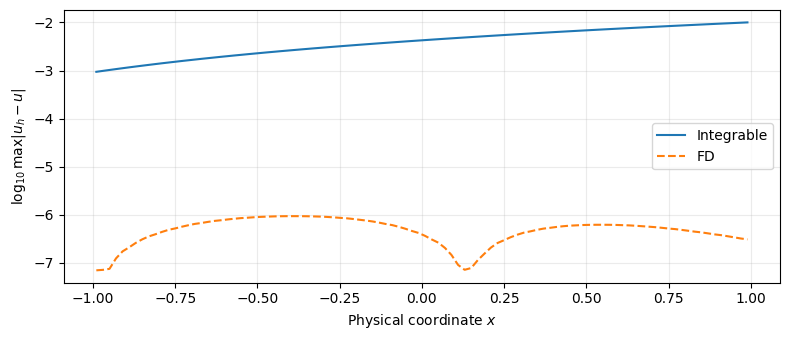

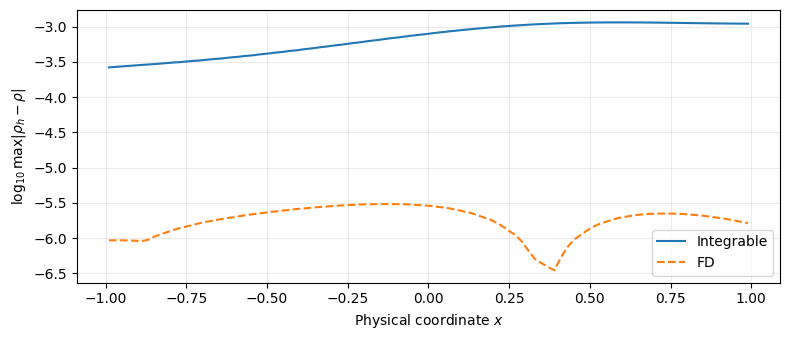

        方案         原表 E_u       原表 E_rho          E_u 与原表之差        E_rho 与原表之差
Integrable 0.010012749797 0.001149674874 2.900457651833e-15 1.110223024625e-16
        FD 0.000000939931 0.000003046421 1.138769634146e-12 1.739719479588e-13


In [14]:
# 式（30）：公共物理网格上的最大绝对误差。
hs_xx = hs_xmin + (hs_xmax - hs_xmin) * np.arange(hs_neval) / (hs_neval - 1)
hs_reference = hs_exact_physical(hs_xx, hs_T)
hs_results, hs_result_rows = {}, []
for hs_name, hs_fields in hs_live_fields.items():
    hs_u = hs_interpolate(hs_fields["x"], hs_fields["u"], hs_xx)
    hs_rho = hs_interpolate(hs_fields["rhoX"], hs_fields["rho"], hs_xx)
    hs_eu = np.abs(hs_u - hs_reference["u"])
    hs_er = np.abs(hs_rho - hs_reference["rho"])
    hs_r = dict(Eu=hs_eu.max(), Erho=hs_er.max(), eu=hs_eu, er=hs_er,
                u=hs_u, rho=hs_rho, minDx=np.diff(hs_fields["x"]).min(),
                minRho=hs_fields["rho"].min())
    hs_results[hs_name] = hs_r
    hs_result_rows.append({"方案": hs_name, "E_u(T)": hs_r["Eu"],
                           "E_rho(T)": hs_r["Erho"], "终点最小格距": hs_r["minDx"],
                           "终点最小密度": hs_r["minRho"]})
print(pd.DataFrame(hs_result_rows).to_string(index=False))

# 每个绘图区间保留其评价点上的最大误差。
hs_bins = 100
hs_centers = hs_xmin + (np.arange(hs_bins) + 0.5) * (hs_xmax - hs_xmin) / hs_bins
hs_bin_index = np.minimum(hs_bins - 1, np.floor(
    (hs_xx - hs_xmin) / (hs_xmax - hs_xmin) * hs_bins).astype(int))
for hs_key, hs_label in (("eu", "u"), ("er", r"\rho")):
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for hs_name, hs_style in (("Integrable", "-"), ("FD", "--")):
        hs_envelope = np.zeros(hs_bins)
        np.maximum.at(hs_envelope, hs_bin_index, hs_results[hs_name][hs_key])
        # 对数图的显示下限为 1e-16；误差范数不截断。
        ax.plot(hs_centers, np.log10(np.maximum(hs_envelope, 1e-16)),
                hs_style, label=hs_name)
    ax.set(xlabel=r"Physical coordinate $x$",
           ylabel=rf"$\log_{{10}}\max|{hs_label}_h-{hs_label}|$")
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.show()

# 仅原配置与原表核对；输出差值，不添加每段完成标记。
hs_is_default = hs_cfg == dict(N=1600, a=0.005, Xleft=-4.0, dt=0.003125,
                              T=0.5, xMin=-1.0, xMax=1.0, evaluationPoints=32001)
if hs_is_default:
    hs_saved = {"Integrable": (0.010012749796509766, 0.0011496748742060303),
                "FD": (9.399310918062342e-7, 3.046420677166317e-6)}
    hs_audit_rows = []
    for hs_name, (hs_expected_u, hs_expected_rho) in hs_saved.items():
        hs_r = hs_results[hs_name]
        hs_audit_rows.append({
            "方案": hs_name, "原表 E_u": hs_expected_u, "原表 E_rho": hs_expected_rho,
            "E_u 与原表之差": abs(hs_r["Eu"] - hs_expected_u),
            "E_rho 与原表之差": abs(hs_r["Erho"] - hs_expected_rho),
        })
    print(pd.DataFrame(hs_audit_rows).to_string(index=False))
    if max(max(row["E_u 与原表之差"], row["E_rho 与原表之差"]) for row in hs_audit_rows) > 1e-8:
        raise ArithmeticError("默认配置与原报告误差不吻合，请检查已编辑的核心代码。")


### 2.2　二孤子

取原文图 4 的参数 $p_1=1.1$、$p_2=1.25$、$q_1=11$、$q_2=5$、$c=1$、$a=0.005$。按原文的相位与坐标平移，连续二孤子的 $\tau$ 函数可写为

$$\begin{aligned}
f&=1+e^{\theta_1}+e^{\theta_2}+A_{12}e^{\theta_1+\theta_2},\qquad
A_{12}=\frac{12}{507},\\
\theta_i&=(p_i-q_i)X+\left(\frac1{p_i}-\frac1{q_i}\right)t+\log6.5,
\end{aligned}\tag{31}$$

物理场与坐标为

$$u=\partial_t^2\log f,\qquad
x=X-\partial_t\log f-\frac1{q_1}-\frac1{q_2},\qquad
\rho=\frac1{1-\partial_X\partial_t\log f}.\tag{32}$$

取 $X_k=-4+ka$、$k=0,\ldots,N$、$N=1600$，由式（32）在 $t=0$ 的值确定初始节点 $x_k^0$ 与场值 $u_k^0$。二孤子采用相同的演化方程，初值和边界均由式（32）给出。

**Integrable。** 初始取 $d_k^0=x_{k+1}^0-x_k^0$、$b_k^0=u_{k+1}^0-u_k^0$，计算

$$\begin{aligned}
\dot d_k&=-b_k,\qquad \dot x_0=-u_0(t),\\
\dot b_k&=2d_k(u_{k+1}+u_k)
+\frac{[d_k^2-a(a-1)]^2-b_k^2}{2d_k}-\frac{d_k}{2},\\
u_{k+1}&=u_k+b_k,\qquad x_{k+1}=x_k+d_k,\qquad
\rho_{k+1/2}=\frac{a}{d_k}.
\end{aligned}\tag{33}$$

左端取 $u_0(t)=\partial_t^2\log f(-4,t)$。

**FD。** 在 $[x_0^0,x_N^0]$ 上均匀取点，令 $u_i^0=u(x_i,0)$、$\rho_i^0=\rho(x_i,0)$、$m_i^0=(D_2u^0)_i+2$，计算

$$\begin{aligned}
\dot m_i&=u_i(D_1m)_i+2m_i(D_1u)_i+\rho_i(D_1\rho)_i,\\
\dot\rho_i&=u_i(D_1\rho)_i+\rho_i(D_1u)_i,\\
u_{i+1}-2u_i+u_{i-1}&=\Delta x^2(m_i-2).
\end{aligned}\tag{34}$$

其中 $D_1,D_2$ 同式（27）；两端取二孤子解析值 $u,\rho,m=u_{xx}+2$，每个时间级联立恢复内部 $u_i$。两种方案均按式（29）作 RK4 更新，取 $\Delta t=0.003125$，从 $t=0$ 计算至 $t=0.5$；误差仍在 $x\in[-1,1]$ 上按式（30）计算。

表 2　二孤子在 t=0.5 时的最大绝对误差。

| 空间方案 | $E_u$ | $E_\rho$ |
| --- | --- | --- |
| 可积半离散（Integrable） | 3.4509e-02 | 3.9932e-03 |
| 中心差分（FD） | 9.6345e-07 | 3.1700e-06 |

计算至 $t=0.5$。FD 的双场误差均较小；Integrable 的 $\rho$ 误差为 FD 的 1259.7 倍。

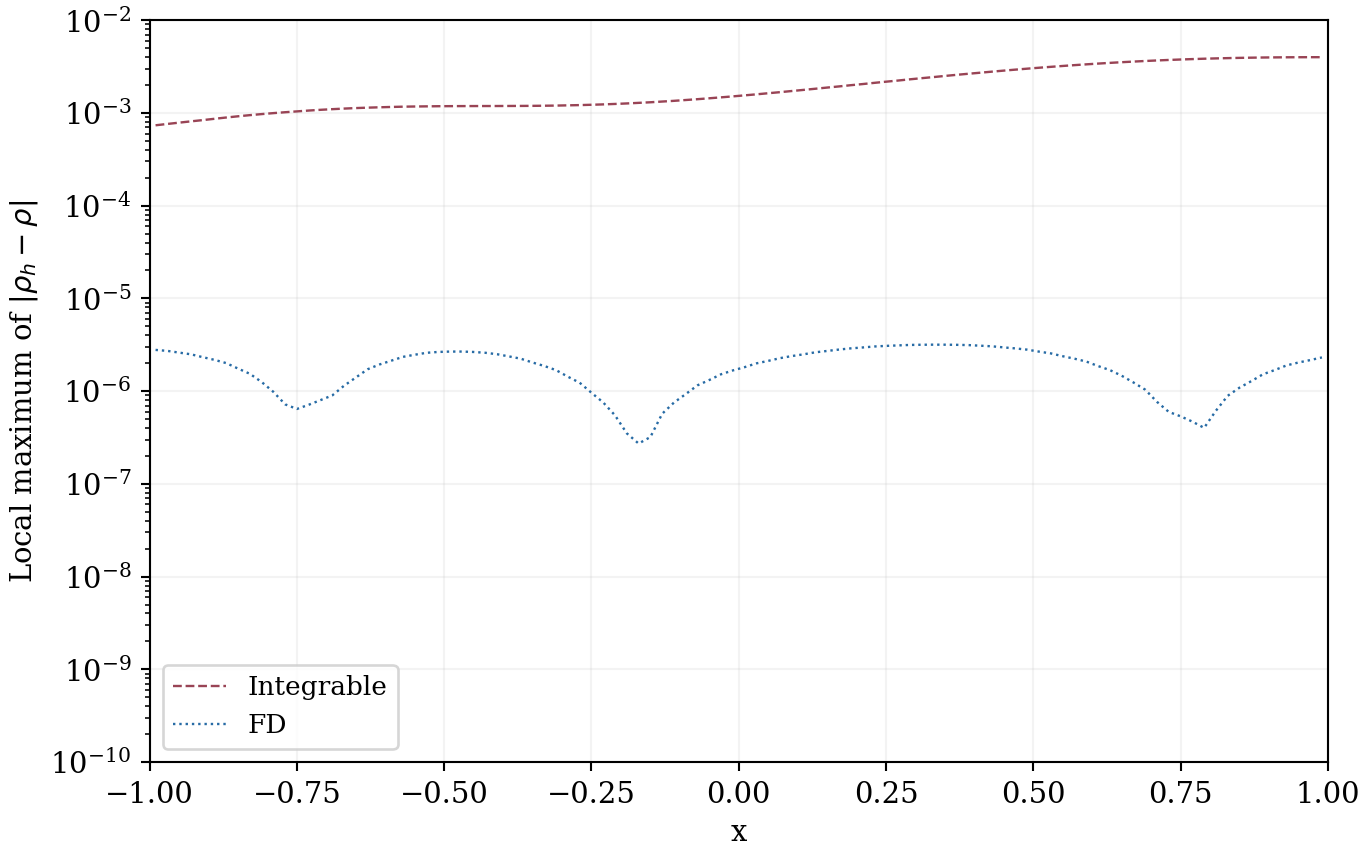

图 3　二孤子在 t=0.5 时的密度误差分布，每段宽 0.02，取段内最大绝对误差。

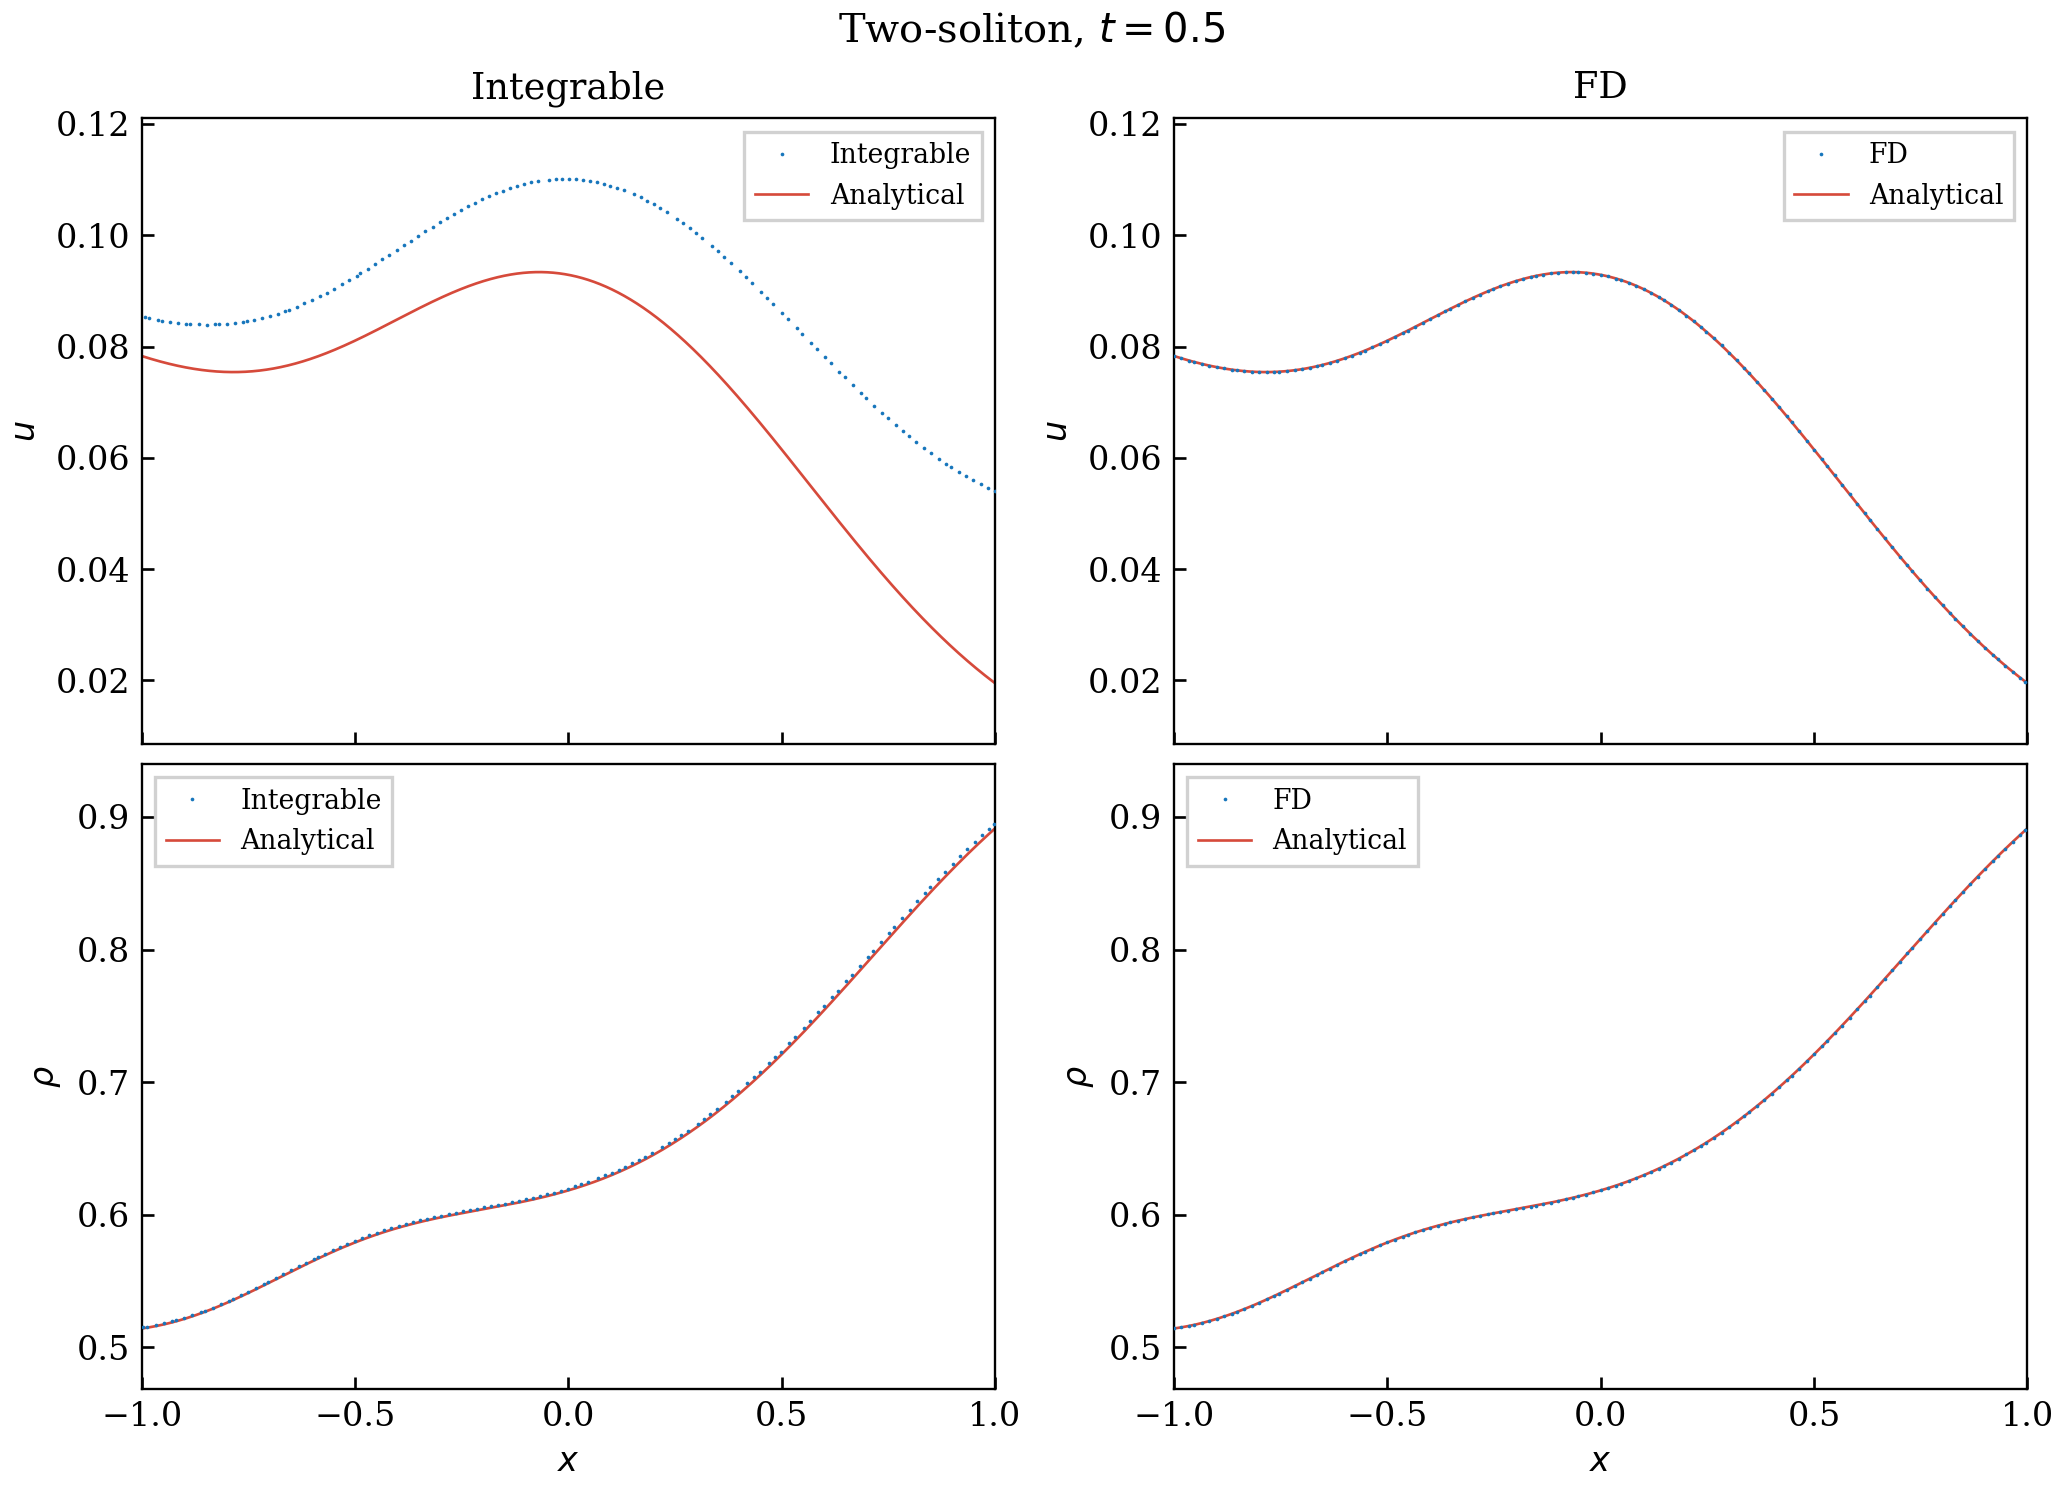

图 4　t=0.5 时的二孤子波形。左列为 Integrable，右列为 FD；上排为 u，下排为 ρ。红色实线为连续解析解，蓝色离散点为对应方案的数值解。

## 3　DLW 空间误差估计的现场计算

这里现场计算 DLW 的纵向空间截断误差：把连续单孤子代入 SD、SDR 与 FD 的方程，比较有限格距残差与其二阶主系数。*计算对象是方程残差，不是第 2 节 2HS 演化至终点的总场误差。*横向与时间导数保持解析，SDR 在相容重构下与 SD 具有相同的理想半离散残差。

取 $K=p+q>0$、$\ell=(p-a)^{-1}+(q+a)^{-1}$、$\Gamma=-(p-a)/(q+a)>0$，令 $z=Kx+\ell y+(q^2-p^2)t+\varphi$、$s(z)=(1+e^{-z})^{-1}$、$f_1(z)=s(z+\log\Gamma)$。同一连续解为

$$u=2K(f_1-s),\qquad v=2K\ell(f_1'+s'),\qquad w=v-u_y=4K\ell s'.$$

以方程左端定义 $\mathcal R_h^S$，则 $\mathcal R_h^S=h^2\tau_y^S+O(h^4)$。第一分量在交错中点展开；第二分量在原节点展开。记 $B(w)=w^2/32-w/4$，由式（8）及其直接差分对照得到

$$\tau_y^{FD}=\begin{pmatrix}v_{xxyy}/12\\u_{xxyyy}/6\end{pmatrix},\qquad
\tau_y^{SD}=\tau_y^{SDR}=\begin{pmatrix}v_{xxyy}/12-u_{xxyyy}/4+B(w)_{xy}\\v_{xxyy}/4-u_{xxyyy}/12+B(w)_{xy}+\tfrac12(u_yu_{yy})_x\end{pmatrix}.$$

所有导数在代码中由 sigmoid 的解析多项式递推求出。令 $\zeta=K\ell$，下列全波形上界来自 $\sup|s'|=1/4$、$\sup|s'''|=1/8$、$\sup|s^{(5)}|=1/4$ 与 $\sup|s''|^2=1/108$：

$$\begin{aligned}
\|\tau_{y,1}^{FD}\|_\infty&\le |\zeta|^3/12,&
\|\tau_{y,2}^{FD}\|_\infty&\le |\zeta|^3/6,\\
\|\tau_{y,1}^{SD}\|_\infty&\le 251|\zeta|^3/864+\zeta^2/8,&
\|\tau_{y,2}^{SD}\|_\infty&\le59|\zeta|^3/96+\zeta^2/8.
\end{aligned}$$

先准备数值环境，再设置谱参数，定义解析剖面、主系数与有限格距残差，最后分别计算主系数表与格距收敛图。每次点击 ▶ 只执行当前可见代码，前段定义在同一笔记本内核中供后段使用。采样最大值覆盖配置中的相位点，解析上界覆盖整个波形。减半格距时，$\|\mathcal R_h/h^2-\tau_y\|$ 应约缩小至四分之一。完整推导见 工作区报告《DLW 误差理论》。

载入 NumPy、pandas 与 Matplotlib，准备双精度残差计算。


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from types import SimpleNamespace
try:
    from IPython.display import display
except ModuleNotFoundError:
    display = print  # 普通 Python 脚本使用文本表；Colab 使用原生表格输出。

# NumPy 使用 IEEE 754 双精度；各段结果保存在 dlw 中。
dlw = SimpleNamespace(ready={"prepare"})

def dlw_require(stage, message):
    if stage not in dlw.ready:
        raise RuntimeError(message)


设置孤子参数、纵向格距 h 和相位采样点。


In [16]:
dlw_require("prepare", "先运行准备环境。")
dlw.ready = {"prepare"}
# 孤子参数 (a,p,q)：A=(2,1,2)，B=(2,4,-3)。
# h：y 方向格距；z：无量纲相位；x、t 导数保持解析。
dlw_cfg = dict(a=2, p=1, q=2, h=1/8,
               zMin=-10, zMax=10, points=1601, levels=3)
a, p, q, h, zMin, zMax = (dlw_cfg[k] for k in
                          ("a", "p", "q", "h", "zMin", "zMax"))
points, levels = dlw_cfg["points"], dlw_cfg["levels"]
if not np.isfinite([a, p, q, h, zMin, zMax]).all():
    raise ValueError("参数必须是有限实数。")
if not (h > 0 and zMax > zMin and zMax-zMin <= 100):
    raise ValueError("要求 h>0、zMax>zMin，且相位区间宽度≤100。")
if (not isinstance(points, int) or not 41 <= points <= 10001 or
        not isinstance(levels, int) or not 1 <= levels <= 6):
    raise ValueError("points 应在 41—10001；levels 应在 1—6，均取整数。")
if h / 2**(levels-1) < 1/1024:
    raise ValueError("最细格距须≥1/1024，以限制浮点消减误差。")
K, P, Q = p+q, p-a, q+a
if not (K > 0 and P != 0 and Q != 0 and -P/Q > 0):
    raise ValueError("单孤子正分支要求 p+q>0，(p-a)(q+a)<0。")
ell, Gamma, Omega = 1/P + 1/Q, -P/Q, q*q-p*p
zeta = K*ell
if not np.isfinite([ell, Gamma, Omega, zeta]).all():
    raise ValueError("参数过近谱极点，所得系数非有限。")
dlw.cfg = dlw_cfg.copy()
dlw.a, dlw.K, dlw.ell, dlw.Gamma = a, K, ell, Gamma
dlw.Omega, dlw.zeta, dlw.h, dlw.levels = Omega, zeta, h, levels
dlw.zs = zMin + (zMax-zMin)*np.arange(points, dtype=np.float64)/(points-1)
dlw.ready = {"prepare", "config"}
display(pd.DataFrame([[K, ell, Gamma, zeta, h, points]],
                     columns=["K", "ℓ", "Γ", "ζ = Kℓ", "h", "相位点数"]))


,K,ℓ,Γ,ζ = Kℓ,h,相位点数
0,3,-0.75,0.25,-2.25,0.125,1601


定义连续单孤子剖面及其对相位的解析导数。


In [17]:
dlw_require("config", "先运行谱参数配置。")
dlw.ready = {"prepare", "config"}
# s^(n)=s(1-s)*P_n(s)，P_(n+1)=(1-2s)P_n+s(1-s)P_n'。
dlw_polys = [np.array([1.0])]
for n in range(1, 5):
    c = dlw_polys[-1]
    dlw_polys.append(np.array([(k+1)*((c[k] if k < len(c) else 0)
                                    -(c[k-1] if k else 0))
                              for k in range(len(c)+1)]))

def dlw_sigmoid_jet(z):
    z = np.asarray(z, dtype=np.float64)
    e = np.exp(-np.abs(z))
    s = np.where(z >= 0, 1/(1+e), e/(1+e))
    theta = e/(1+e)**2
    return np.array([s] + [theta*np.polynomial.polynomial.polyval(s, c)
                          for c in dlw_polys])

def dlw_profile(z):
    s, f = dlw_sigmoid_jet(z), dlw_sigmoid_jet(z+np.log(dlw.Gamma))
    # u[n]、v[n] 表示对 z 的 n 阶导数，支持标量或整列相位。
    return dict(s=s, f=f, u=2*dlw.K*(f[:4]-s[:4]),
                v=2*dlw.K*dlw.ell*(f[1:4]+s[1:4]))

dlw.profile = dlw_profile
dlw.ready = {"prepare", "config", "profile"}


定义二阶残差主系数及全波形上界。


In [18]:
dlw_require("profile", "先运行连续剖面。")
dlw.ready = {"prepare", "config", "profile"}

def dlw_coefficient(z):
    c = dlw.profile(z)
    s, f, zeta = c["s"], c["f"], dlw.zeta
    d1, d2, d3 = f[1]-s[1], f[2]-s[2], f[3]-s[3]
    # B=(s″)²+s′*s‴=0.5*((s′)²)″。
    B = s[2]**2 + s[1]*s[3]
    return {
        "FD": np.array([zeta**3*(f[5]+s[5])/6,
                        zeta**3*(f[5]-s[5])/3]),
        "SD": np.array([zeta**3*((2*s[5]-f[5])/3+B)-zeta**2*s[3],
                        zeta**3*((f[5]+2*s[5])/3+B+2*(d2*d2+d1*d3))
                        -zeta**2*s[3]])
    }

# 解析上界覆盖全部实相位 z，不依赖相位区间与采样点数。
Z = abs(dlw.zeta)
dlw.bounds = {"FD": np.array([Z**3/12, Z**3/6]),
              "SD": np.array([251*Z**3/864+Z**2/8,
                              59*Z**3/96+Z**2/8])}
dlw.coefficient = dlw_coefficient
dlw.ready = {"prepare", "config", "profile", "coefficient"}


定义有限格距 h 下的 SD 和 FD 方程残差。


In [19]:
dlw_require("coefficient", "先运行二阶主系数。")
dlw.ready = {"prepare", "config", "profile", "coefficient"}

def dlw_residual(z, hh, scheme):
    if scheme not in ("SD", "FD"):
        raise ValueError("scheme 应为 SD 或 FD。")
    z = np.asarray(z, dtype=np.float64)
    a, K, ell, Omega = dlw.a, dlw.K, dlw.ell, dlw.Omega
    cache = {}

    def node(j):
        if j in cache:
            return cache[j]
        c = dlw.profile(z+ell*hh*j)
        plus = dlw.profile(z+ell*hh*(j+1))
        minus = dlw.profile(z+ell*hh*(j-1))
        # 每个偏移节点重新构造 D=δ₀u、W=v−δ₀u。
        D = (plus["u"][:3]-minus["u"][:3])/(2*hh)
        W = c["v"]-D
        u = c["u"]
        Ax = K*(u[0]+2*a)*u[1]
        Hx = Ax + (hh*hh*K*(W[0]/16-1/4)*W[1] if scheme == "SD" else 0)
        out = dict(c, D=D, W=W, Ax=Ax, Hx=Hx)
        cache[j] = out
        return out

    # 第一式在交错中点，第二式在节点 j=0；x、t 导数保持解析。
    plus, minus, c = node(1/2), node(-1/2), node(0)
    r1 = Omega*(plus["u"][1]-minus["u"][1])/hh
    r1 += (plus["Hx"]-minus["Hx"])/hh
    r1 += K*K*((plus["u"][2]-minus["u"][2])/hh
               +(plus["W"][2]+minus["W"][2])/2 if scheme == "SD"
               else (plus["v"][2]+minus["v"][2])/2)
    u, v, W, D = c["u"], c["v"], c["W"], c["D"]
    r2 = Omega*v[1]
    if scheme == "SD":
        pp, mm = node(1), node(-1)
        r2 += ((pp["Hx"]-mm["Hx"])/(2*hh)
               +K*(u[1]*W[0]+(u[0]+2*a)*W[1]-4*u[1])
               +K*K*(D[2]+(pp["W"][2]-2*W[2]+mm["W"][2])/4))
    else:
        r2 += K*(u[1]*v[0]+(u[0]+2*a)*v[1]-4*u[1])+K*K*D[2]
    return np.array([r1, r2])

dlw.residual = dlw_residual
dlw.ready = {"prepare", "config", "profile", "coefficient", "residual"}


计算采样主系数，核对上界并测量连续方程残差。


In [20]:
dlw_require("residual", "先运行有限格距残差。")
dlw.ready = {"prepare", "config", "profile", "coefficient", "residual"}
dlw.tau = dlw.coefficient(dlw.zs)
c = dlw.profile(dlw.zs)
u, v, b = c["u"], c["v"], c["u"][0]+2*dlw.a
K, ell, Omega = dlw.K, dlw.ell, dlw.Omega
terms1 = np.array([ell*Omega*u[2], K*K*v[2],
                   K*ell*(u[1]*u[1]+b*u[2])])
terms2 = np.array([Omega*v[1], K*K*ell*u[3],
                   K*(u[1]*v[0]+b*v[1]-4*u[1])])
# 两条连续方程的归一化残差 abs(sum)/(1+sum(abs))。
dlw.continuumDefect = max(float(np.max(np.abs(terms.sum(axis=0))
                                     /(1+np.abs(terms).sum(axis=0))))
                          for terms in (terms1, terms2))
if dlw.continuumDefect > 1e-10:
    raise ArithmeticError("连续 DLW 方程核对失败，请检查剖面或谱参数。")
dlw.coeffRows = []
for S in ("SD", "FD"):
    for i in range(2):
        sampled = float(np.max(np.abs(dlw.tau[S][i])))
        bound = float(dlw.bounds[S][i])
        if not np.isfinite(sampled) or sampled > bound*(1+1e-10):
            raise ArithmeticError(f"{S} 第 {i+1} 式超出解析主系数上界。")
        dlw.coeffRows.append([f"{S}{' / SDR' if S == 'SD' else ''} · {i+1}",
                              sampled, bound, dlw.h**2*sampled, dlw.h**2*bound])
display(pd.DataFrame(dlw.coeffRows, columns=["方程", "采样 max |τ|", "全波形解析上界",
                                           "采样 h² max |τ|", "h² 解析上界"]))
print("continuumDefect =", dlw.continuumDefect)
dlw.ready = {"prepare", "config", "profile", "coefficient", "residual", "main"}


,方程,采样 max |τ|,全波形解析上界,采样 h² max |τ|,h² 解析上界
0,SD / SDR · 1,1.686064340168,3.94189453125,0.026344755315,0.061592102051
1,SD / SDR · 2,0.933154023319,7.63330078125,0.014580531614,0.119270324707
2,FD · 1,0.259897349713,0.94921875000,0.004060896089,0.014831542969
3,FD · 2,1.395719281105,1.89843750000,0.021808113767,0.029663085938


continuumDefect = 4.286812441877563e-15


逐次减半格距，比较并绘制缩放残差与主系数。


,方程,h,采样 max |R_h / h²|,采样 max |R_h / h² − τ|,减半收敛阶
0,SD · 1,0.12500,1.678800403713,0.007335764558,NaN
1,SD · 2,0.12500,0.925565124167,0.013112246747,NaN
2,FD · 1,0.12500,0.259721281505,0.000244599175,NaN
3,FD · 2,0.12500,1.393148642247,0.002665338977,NaN
4,SD · 1,0.06250,1.684244275313,0.001838102143,1.996730396751
5,SD · 2,0.06250,0.931249000112,0.003293108612,1.993392908294
6,FD · 1,0.06250,0.259853306611,0.000061189634,1.999060372016
7,FD · 2,0.06250,1.395075853309,0.000666981567,1.998600229383
8,SD · 1,0.03125,1.685609068294,0.000459786201,1.999181866924
9,SD · 2,0.03125,0.932677279031,0.000824221048,1.998346884209


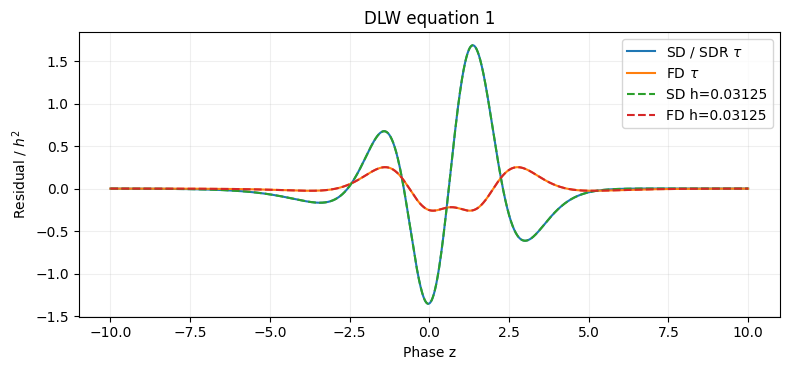

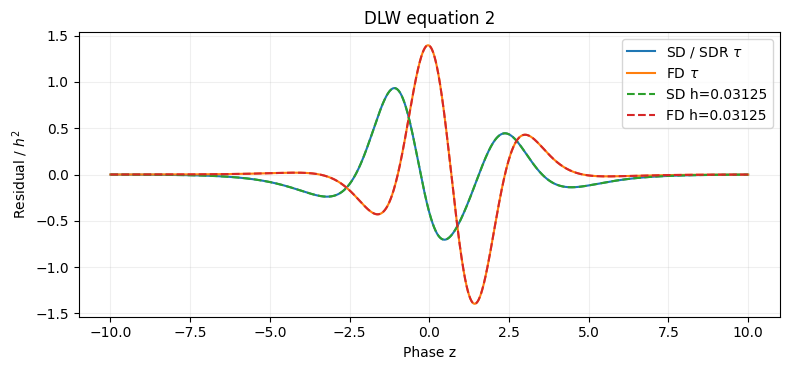

In [21]:
dlw_require("main", "先运行主系数计算。")
dlw.ready = {"prepare", "config", "profile", "coefficient", "residual", "main"}
# R_h/h²−τ=O(h²)：相邻两档误差之比应趋近 4。
dlw.convergence, dlw.finest, previous = [], {}, {}
for level in range(dlw.levels):
    hh = dlw.h/2**level
    for S in ("SD", "FD"):
        values = dlw.residual(dlw.zs, hh, S)/(hh*hh)
        if not np.isfinite(values).all():
            raise ArithmeticError("有限 h 残差非有限，请检查参数。")
        errors = values-dlw.tau[S]
        for i in range(2):
            err = float(np.max(np.abs(errors[i])))
            old = previous.get((S, i))
            rate = np.log2(old/err) if old is not None and old > 0 and err > 0 else np.nan
            dlw.convergence.append([f"{S} · {i+1}", hh,
                                    float(np.max(np.abs(values[i]))), err, rate])
            previous[S, i] = err
        if level == dlw.levels-1:
            dlw.finest[S] = values
display(pd.DataFrame(dlw.convergence, columns=["方程", "h", "采样 max |R_h / h²|",
                                             "采样 max |R_h / h² − τ|", "减半收敛阶"]))
for i in range(2):
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.plot(dlw.zs, dlw.tau["SD"][i], label=r"SD / SDR $\tau$")
    ax.plot(dlw.zs, dlw.tau["FD"][i], label=r"FD $\tau$")
    hh = dlw.h/2**(dlw.levels-1)
    ax.plot(dlw.zs, dlw.finest["SD"][i], "--", label=f"SD h={hh:g}")
    ax.plot(dlw.zs, dlw.finest["FD"][i], "--", label=f"FD h={hh:g}")
    ax.set(title=f"DLW equation {i+1}", xlabel="Phase z", ylabel=r"Residual / $h^2$")
    ax.grid(alpha=.2)
    ax.legend()
    fig.tight_layout()
    plt.show()
dlw.ready = {"prepare", "config", "profile", "coefficient", "residual", "main", "convergence"}
